# Project Introduction

The City of Seattle aims to become carbon‑neutral by **2050**. A key lever in this transition is the energy performance of **non‑residential buildings**, which together account for a substantial share of municipal electricity use and **CO₂ emissions**.

In **2016** the city conducted an extensive field survey that measured **total energy consumption** and associated **CO₂ emissions** for a representative sample of commercial, institutional, and industrial structures. Because these measurements are costly and time‑consuming, we will develop a **predictive model** that estimates:

- **Energy use (kWh)**
- **CO₂ emissions (kg)**  

for the many buildings that have not yet been measured.

Our approach relies solely on **structural attributes** that are readily available for every building—size, age, primary use, geographic location, HVAC system, insulation level, etc.  

## Workflow

1. **Exploratory Data Analysis**  
   - Uncover patterns and key drivers.  

2. **Supervised Learning**  
   - Train and evaluate several regression models.  

3. **Feature‑Importance Analysis**  
   - Identify the most influential factors for the best‑performing model.  

## Deliverable

A **reproducible Jupyter notebook** that can be applied city‑wide, enabling the Seattle Planning Department to:

- Prioritize retrofits  
- Set realistic energy‑reduction targets  
- Monitor progress toward the 2050 carbon‑neutral goal


In [1]:
import pandas as pd

# Load the dataset
data = pd.read_csv(r'C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\data\2016_Building_Energy_Benchmarking.csv')

# Explore the data
print(data.head())
print(data.info())


   OSEBuildingID  DataYear    BuildingType PrimaryPropertyType  \
0              1      2016  NonResidential               Hotel   
1              2      2016  NonResidential               Hotel   
2              3      2016  NonResidential               Hotel   
3              5      2016  NonResidential               Hotel   
4              8      2016  NonResidential               Hotel   

                  PropertyName          Address     City State  ZipCode  \
0         Mayflower park hotel    405 Olive way  Seattle    WA  98101.0   
1              Paramount Hotel  724 Pine street  Seattle    WA  98101.0   
2      5673-The Westin Seattle  1900 5th Avenue  Seattle    WA  98101.0   
3                    HOTEL MAX   620 STEWART ST  Seattle    WA  98101.0   
4  WARWICK SEATTLE HOTEL (ID8)    401 LENORA ST  Seattle    WA  98121.0   

  TaxParcelIdentificationNumber  ...  Electricity(kWh) Electricity(kBtu)  \
0                    0659000030  ...      1.156514e+06         3946027.0   


In [2]:
import pandas as pd
from openpyxl import Workbook
from openpyxl.worksheet.table import Table, TableStyleInfo

# Prepare a list to hold variable analysis results
analysis_results = []

# Analyze each variable in the DataFrame
for column in data.columns:
    original_dtype = str(data[column].dtype)
    proposed_dtype = 'category' if data[column].nunique() < 10 else 'float'
    num_unique_values = data[column].nunique()
    unique_values = data[column].unique() if num_unique_values < 10 else None
    fill_rate = data[column].count() / len(data)  # Calculate fill rate

    # Append analysis result to the list
    analysis_results.append({
        'Variable Name': column,
        'Original Data Type': original_dtype,
        'Proposed Data Type': proposed_dtype,
        'Number of Unique Values': num_unique_values,
        'Unique Values': unique_values,
        'Fill Rate': fill_rate  # Add fill rate
    })

# Create a DataFrame from the analysis results
analysis_df = pd.DataFrame(analysis_results)

# Specify your desired path
file_path = r'C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\variable_analysis.xlsx'

# Write to Excel with formatting
with pd.ExcelWriter(file_path, engine='openpyxl') as writer:
    analysis_df.to_excel(writer, index=False, sheet_name='Variable Analysis')
    
    # Access workbook and worksheet
    workbook = writer.book
    worksheet = writer.sheets['Variable Analysis']
    
    # Define table range (adjust according to the DataFrame size)
    table_range = f"A1:F{len(analysis_df) + 1}"  # Update range to include Fill Rate
    
    # Create Excel table
    excel_table = Table(displayName="VariableAnalysis", ref=table_range)
    
    # Apply grey and white styling
    style = TableStyleInfo(
        name="TableStyleMedium6",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=True
    )
    excel_table.tableStyleInfo = style
    
    # Add table to worksheet
    worksheet.add_table(excel_table)

print(f"Variable analysis saved as a formatted grey and white table in {file_path}")


Variable analysis saved as a formatted grey and white table in C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\variable_analysis.xlsx


In [3]:
import pandas as pd
from openpyxl import Workbook
from openpyxl.worksheet.table import Table, TableStyleInfo



# Select first 200 rows
subset_data = data.head(200)

# Write to Excel with formatting
output_path = r"C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\first_200_rows.xlsx"
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    subset_data.to_excel(writer, index=False, sheet_name='First 200 Rows')
    
    # Access workbook and worksheet
    workbook = writer.book
    worksheet = writer.sheets['First 200 Rows']
    
    # Define the table range
    table_range = f"A1:{chr(64 + len(subset_data.columns))}{len(subset_data) + 1}"
    
    # Create Excel table
    excel_table = Table(displayName="First200Rows", ref=table_range)
    
    # Apply grey and white styling
    style = TableStyleInfo(
        name="TableStyleMedium6",  # Grey and white styling
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=True
    )
    excel_table.tableStyleInfo = style
    
    # Add table to worksheet
    worksheet.add_table(excel_table)

print(f"Excel file saved with grey table formatting: {output_path}")


Excel file saved with grey table formatting: C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\first_200_rows.xlsx


In [4]:
# Define columns to drop
columns_to_drop = [
    'OSEBuildingID', 'DataYear', 'PropertyName', 'Address', 'City', 
    'State', 'TaxParcelIdentificationNumber', 'CouncilDistrictCode',
    'Neighborhood', 'Latitude', 'Longitude', 'PropertyGFATotal',
    'ListOfAllPropertyUseTypes', 'YearsENERGYSTARCertified',
    'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)',
    'SourceEUIWN(kBtu/sf)', 'Electricity(kWh)', 'NaturalGas(therms)',
    'DefaultData', 'Comments', 'ComplianceStatus', 'GHGEmissionsIntensity','PrimaryPropertyType'
]  # Removed the extra single quote at the end

# Drop specified columns
data = data.drop(columns=columns_to_drop, errors='ignore')

import pandas as pd

# Step 1: Analyze and filter the 'building type' field
building_type_column = 'BuildingType'  # replace with actual column name for building type
before_count = data.shape[0]

building_type_counts = data[building_type_column].value_counts()
single_occurrences = building_type_counts[building_type_counts == 1].index
data = data[~data[building_type_column].isin(single_occurrences)]
after_count = data.shape[0]

print(f"Lines before removing single occurrence building types: {before_count}")
print(f"Lines after removing single occurrence building types: {after_count}")

Lines before removing single occurrence building types: 3376
Lines after removing single occurrence building types: 3375


Initial row count: 3375
Rows impacted by imputation: 5


C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\3201397486.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['SiteEnergyUseWN(kBtu)'].replace(0, pd.NA, inplace=True)
C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\3201397486.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['SiteEnergyUseWN(

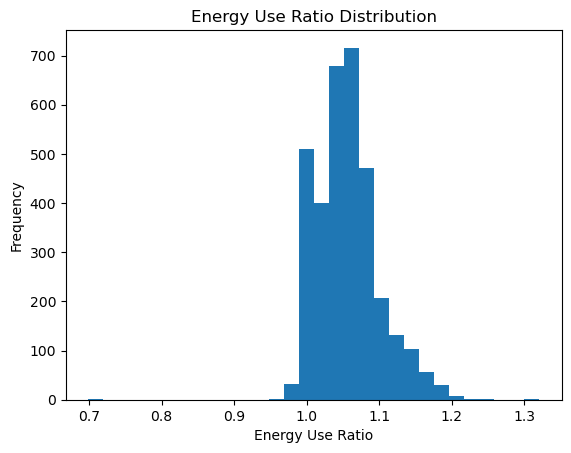

Rows impacted by filtering: 23
Final row count after dropping columns: 3352


In [5]:
import pandas as pd
import matplotlib.pyplot as plt


# Step 1: Initial count of rows
initial_count = data.shape[0]
print(f"Initial row count: {initial_count}")

# Step 2: Impute missing/zero values
data['SiteEnergyUseWN(kBtu)'].replace(0, pd.NA, inplace=True)
data['SiteEnergyUseWN(kBtu)'].fillna(data['SiteEnergyUse(kBtu)'], inplace=True)

# Count rows affected by imputation
imputation_count = data['SiteEnergyUseWN(kBtu)'].isna().sum()
print(f"Rows impacted by imputation: {imputation_count}")

# Step 3: Calculate ratio and visualize
data['EnergyUseRatio'] = data['SiteEnergyUseWN(kBtu)'] / data['SiteEnergyUse(kBtu)']

# Plot histogram of the Energy Use Ratio
plt.hist(data['EnergyUseRatio'].dropna(), bins=30)
plt.title('Energy Use Ratio Distribution')
plt.xlabel('Energy Use Ratio')
plt.ylabel('Frequency')
plt.show()

# Step 4: Filter out rows with 0 or NaN in SiteEnergyUseWN(kBtu)
filtered_data = data[data['SiteEnergyUseWN(kBtu)'].notna() & (data['SiteEnergyUseWN(kBtu)'] != 0)]
filtered_count = data.shape[0] - filtered_data.shape[0]
print(f"Rows impacted by filtering: {filtered_count}")

# Step 5: Drop unnecessary columns
data = filtered_data.drop(columns=['SiteEnergyUse(kBtu)', 'EnergyUseRatio'])
final_count = data.shape[0]
print(f"Final row count after dropping columns: {final_count}")


In [6]:
import pandas as pd



# Step 1: Check initial data size
initial_count = data.shape[0]
print(f"Initial row count: {initial_count}")

# Step 2: Remove outlier observations
outlier_count = data[data['Outlier'].isin(['High outlier', 'Low outlier'])].shape[0]
data = data[~data['Outlier'].isin(['High outlier', 'Low outlier'])]

print(f"Rows removed: {outlier_count}")
print(f"Rows remaining: {data.shape[0]}")

# Step 3: Drop the Outlier column
# Remove outliers and drop column in one operation
data = data[~data['Outlier'].isin(['High outlier', 'Low outlier'])].drop(columns=['Outlier'])


print(f"Final dataset shape: {data.shape}")


Initial row count: 3352
Rows removed: 32
Rows remaining: 3320
Final dataset shape: (3320, 19)


In [7]:
data.head()


,BuildingType,ZipCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
0,NonResidential,98101.0,1927,1.0,12,0,88434,Hotel,88434.0,NaN,NaN,NaN,NaN,60.0,7456910.0,2003882.00,3946027.0,1276453.0,249.98
1,NonResidential,98101.0,1996,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8664479.0,0.00,3242851.0,5145082.0,295.86
2,NonResidential,98101.0,1969,1.0,41,196718,759392,Hotel,756493.0,NaN,NaN,NaN,NaN,43.0,73937112.0,21566554.00,49526664.0,1493800.0,2089.28
3,NonResidential,98101.0,1926,1.0,10,0,61320,Hotel,61320.0,NaN,NaN,NaN,NaN,56.0,6946800.5,2214446.25,2768924.0,1811213.0,286.43
4,NonResidential,98121.0,1980,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14656503.0,0.00,5368607.0,8803998.0,505.01


In [8]:
import pandas as pd

# Count original dimensions
original_row_count = data.shape[0]
original_col_count = data.shape[1]

# Apply data cleaning (example: removing specific entries)
data = data[~data['BuildingType'].str.contains('Multifamily', case=False, na=False)]

# Count new dimensions
new_row_count = data.shape[0]
new_col_count = data.shape[1]

# Calculate impact
impacted_rows = original_row_count - new_row_count
impacted_columns = original_col_count - new_col_count

# Display systematic tracking results
print(f"Original rows: {original_row_count}")
print(f"New rows: {new_row_count}")
print(f"Impacted rows: {impacted_rows}")
print(f"Total columns: {original_col_count}")




Original rows: 3320
New rows: 1632
Impacted rows: 1688
Total columns: 19


In [9]:
data.head()


,BuildingType,ZipCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
0,NonResidential,98101.0,1927,1.0,12,0,88434,Hotel,88434.0,NaN,NaN,NaN,NaN,60.0,7456910.0,2003882.00,3946027.0,1276453.0,249.98
1,NonResidential,98101.0,1996,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8664479.0,0.00,3242851.0,5145082.0,295.86
2,NonResidential,98101.0,1969,1.0,41,196718,759392,Hotel,756493.0,NaN,NaN,NaN,NaN,43.0,73937112.0,21566554.00,49526664.0,1493800.0,2089.28
3,NonResidential,98101.0,1926,1.0,10,0,61320,Hotel,61320.0,NaN,NaN,NaN,NaN,56.0,6946800.5,2214446.25,2768924.0,1811213.0,286.43
4,NonResidential,98121.0,1980,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14656503.0,0.00,5368607.0,8803998.0,505.01


In [10]:
# ==== Step X: convert variables to their proposed data types ====

type_map = {
    "BuildingType": "category",
    "ZipCode": "object",
    "NumberofBuildings": "int64",
    "LargestPropertyUseTypeGFA": "int64",
    "SecondLargestPropertyUseTypeGFA": "int64",
    "ThirdLargestPropertyUseTypeGFA": "int64",
    "ENERGYSTARScore": "int64",
    "SiteEnergyUseWN(kBtu)": "int64",
    "SteamUse(kBtu)": "int64",
    "Electricity(kBtu)": "int64",
    "NaturalGas(kBtu)": "int64",
    "TotalGHGEmissions": "int64"
}

# Apply conversions safely
for col, dtype in type_map.items():
    if col not in data.columns:
        print(f"⚠️ Skipping '{col}' — not found in dataframe.")
        continue
    try:
        if dtype == "category":
            data[col] = data[col].astype("category")
        elif dtype == "int64":
            # Handle non-integer values and missing data safely
            data[col] = pd.to_numeric(data[col], errors="coerce").astype("Int64")
        else:
            data[col] = data[col].astype(dtype)
        print(f"✅ Converted {col} → {dtype}")
    except Exception as e:
        print(f"❌ Could not convert {col} → {dtype} ({e})")

# Confirm
data.dtypes.loc[list(type_map.keys())]


✅ Converted BuildingType → category
✅ Converted ZipCode → object
✅ Converted NumberofBuildings → int64
✅ Converted LargestPropertyUseTypeGFA → int64
❌ Could not convert SecondLargestPropertyUseTypeGFA → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert ThirdLargestPropertyUseTypeGFA → int64 (cannot safely cast non-equivalent float64 to int64)
✅ Converted ENERGYSTARScore → int64
❌ Could not convert SiteEnergyUseWN(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert SteamUse(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert Electricity(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert NaturalGas(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert TotalGHGEmissions → int64 (cannot safely cast non-equivalent object to int64)


BuildingType                       category
ZipCode                              object
NumberofBuildings                     Int64
LargestPropertyUseTypeGFA             Int64
SecondLargestPropertyUseTypeGFA     float64
ThirdLargestPropertyUseTypeGFA      float64
ENERGYSTARScore                       Int64
SiteEnergyUseWN(kBtu)               float64
SteamUse(kBtu)                      float64
Electricity(kBtu)                   float64
NaturalGas(kBtu)                    float64
TotalGHGEmissions                   float64
dtype: object

In [11]:
import pandas as pd
import numpy as np

UNAVAILABLE = {"", "na", "n/a", "none", "null", "nan", "not available", "not_available", "0", "0.0", "unknown"}

def is_unavailable_type(s: pd.Series) -> pd.Series:
    s2 = s.astype(str).str.strip().str.lower()
    return s.isna() | s2.isin(UNAVAILABLE)

def is_positive_gfa(s: pd.Series) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce")
    return s_num > 0

pairs = [
    ("LargestPropertyUseType", "LargestPropertyUseTypeGFA"),
    ("SecondLargestPropertyUseType", "SecondLargestPropertyUseTypeGFA"),
    ("ThirdLargestPropertyUseType", "ThirdLargestPropertyUseTypeGFA"),
]

for col_type, col_gfa in pairs:
    if col_type not in data.columns or col_gfa not in data.columns:
        print(f"⚠️ Skipping: {col_type} or {col_gfa} not found")
        continue

    type_unavail = is_unavailable_type(data[col_type])
    type_has_value = ~type_unavail
    gfa_pos = is_positive_gfa(data[col_gfa])

    # --- Fix rule ---
    # If Type has value but GFA is not positive → make Type empty
    mask_fix = type_has_value & ~gfa_pos
    n_fix = mask_fix.sum()
    data.loc[mask_fix, col_type] = np.nan  # clear value

    print(f"✅ {col_type}: cleared {n_fix} inconsistent entries (Type had value but GFA≤0/NaN)")


✅ LargestPropertyUseType: cleared 0 inconsistent entries (Type had value but GFA≤0/NaN)
✅ SecondLargestPropertyUseType: cleared 77 inconsistent entries (Type had value but GFA≤0/NaN)
✅ ThirdLargestPropertyUseType: cleared 24 inconsistent entries (Type had value but GFA≤0/NaN)


In [12]:
import pandas as pd
import numpy as np

summary = pd.DataFrame({
    "NaN_Count": data.isna().sum(),
    "NaN_%": (data.isna().mean() * 100).round(2)
})

# Add zero stats for numeric columns only
numeric_cols = data.select_dtypes(include=[np.number]).columns
summary["Zero_Count"] = 0
summary.loc[numeric_cols, "Zero_Count"] = (data[numeric_cols] == 0).sum().values
summary["Zero_%"] = 0
summary.loc[numeric_cols, "Zero_%"] = ((data[numeric_cols] == 0).mean() * 100).round(2).values

# Sort by highest missingness
summary = summary.sort_values(["NaN_%", "Zero_%"], ascending=[False, False])

display(summary)


C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\2075506142.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '<FloatingArray>
[  0.0,  3.19,  0.98, 79.72,   0.0,   0.0,  4.72,  1.47,   0.0,   0.0, 93.01,
  0.12, 27.82,  0.06]
Length: 14, dtype: Float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  summary.loc[numeric_cols, "Zero_%"] = ((data[numeric_cols] == 0).mean() * 100).round(2).values


,NaN_Count,NaN_%,Zero_Count,Zero_%
ThirdLargestPropertyUseType,1305,79.96,0,0.0
ThirdLargestPropertyUseTypeGFA,1281,78.49,24,1.47
SecondLargestPropertyUseType,862,52.82,0,0.0
SecondLargestPropertyUseTypeGFA,785,48.10,77,4.72
ENERGYSTARScore,550,33.70,0,0.0
ZipCode,16,0.98,0,0.0
LargestPropertyUseType,4,0.25,0,0.0
LargestPropertyUseTypeGFA,4,0.25,0,0.0
SteamUse(kBtu),0,0.00,1518,93.01
PropertyGFAParking,0,0.00,1301,79.72


In [13]:
import pandas as pd
import numpy as np

# Define the target variables to check
targets = ["TotalGHGEmissions", "SiteEnergyUseWN(kBtu)"]

before = len(data)

# Keep only rows where BOTH targets > 0 and not NaN
mask_valid = (data[targets] > 0).all(axis=1)
mask_valid &= data[targets].notna().all(axis=1)

data = data.loc[mask_valid].copy()
after = len(data)

print(f"✅ Removed {before - after} rows where any target variable was 0 or NaN")
print(f"Remaining rows: {after}")


✅ Removed 2 rows where any target variable was 0 or NaN
Remaining rows: 1630


In [14]:
gfa_cols = [
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseTypeGFA"
]

for col in gfa_cols:
    if col in data.columns:
        n_missing = data[col].isna().sum()
        data[col] = data[col].fillna(0)
        print(f"✅ Replaced {n_missing} NaN values with 0 in '{col}'")
    else:
        print(f"⚠️ Column '{col}' not found — skipped.")


✅ Replaced 4 NaN values with 0 in 'LargestPropertyUseTypeGFA'
✅ Replaced 784 NaN values with 0 in 'SecondLargestPropertyUseTypeGFA'
✅ Replaced 1280 NaN values with 0 in 'ThirdLargestPropertyUseTypeGFA'


In [15]:
if "ZipCode" in data.columns:
    n_missing = data["ZipCode"].isna().sum()
    data["ZipCode"] = data["ZipCode"].fillna("unknown")
    print(f"✅ Replaced {n_missing} NaN values in 'ZipCode' with 'unknown'")
else:
    print("⚠️ 'ZipCode' column not found in data")



✅ Replaced 16 NaN values in 'ZipCode' with 'unknown'


In [16]:
import numpy as np
import pandas as pd

# Identify numeric columns
num_cols = data.select_dtypes(include=[np.number]).columns

for col in num_cols:
    # Count NaNs before conversion
    n_missing = data[col].isna().sum()
    
    # Round to nearest whole number
    data[col] = np.floor(data[col] + 0.5)  # same as round() but avoids dtype issues
    
    # Convert to nullable integer type
    data[col] = data[col].astype("Int64")
    
    print(f"✅ Converted '{col}' to whole numbers (Int64), preserved {n_missing} NaNs.")


✅ Converted 'YearBuilt' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'NumberofBuildings' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'NumberofFloors' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'PropertyGFAParking' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'PropertyGFABuilding(s)' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'LargestPropertyUseTypeGFA' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'SecondLargestPropertyUseTypeGFA' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'ThirdLargestPropertyUseTypeGFA' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'ENERGYSTARScore' to whole numbers (Int64), preserved 550 NaNs.
✅ Converted 'SiteEnergyUseWN(kBtu)' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'SteamUse(kBtu)' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'Electricity(kBtu)' to whole numbers (Int64), preserved 0 NaNs.
✅ Converted 'NaturalGas(kBtu)' to whole numbers (Int64), 

In [17]:
# Display summary without decimals
desc = data.describe().applymap(lambda x: int(x) if pd.notna(x) else x)
display(desc)


C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\3845599723.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  desc = data.describe().applymap(lambda x: int(x) if pd.notna(x) else x)


,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
count,1630,1630,1630,1630,1630,1630,1630,1630,1080,1630,1630,1630,1630,1630
mean,1962,1,4,13156,106158,98757,18808,3210,65,8789221,523893,5920307,2004537,188
std,32,2,6,42713,285576,278291,51210,18166,28,30902252,5574005,20987303,9469382,759
min,1900,0,0,0,3636,0,0,0,1,58114,0,0,0,0
25%,1930,1,1,0,28375,25500,0,0,48,1366622,0,743761,0,21
50%,1966,1,2,0,47160,43525,0,0,73,2787996,0,1642951,525647,51
75%,1989,1,4,0,95306,92004,12863,0,89,7338307,0,4971463,1530282,145
max,2015,111,99,512608,9320156,9320156,639931,459748,100,873923712,134943456,657074389,297909000,16871


# HISTOGRAMS

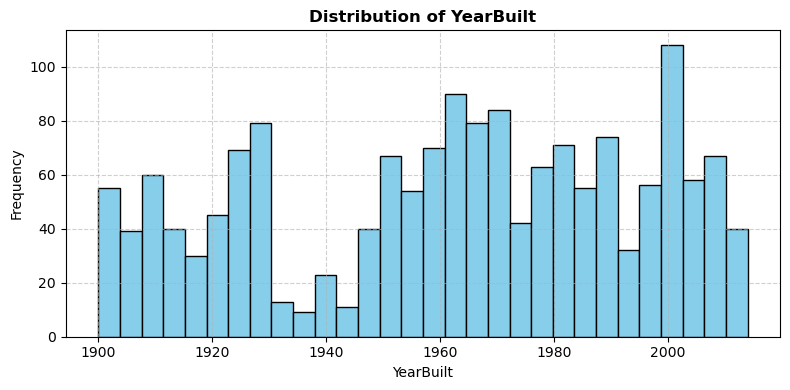

✅ Displayed histogram for YearBuilt (trimmed 1st–99th percentile for clarity)


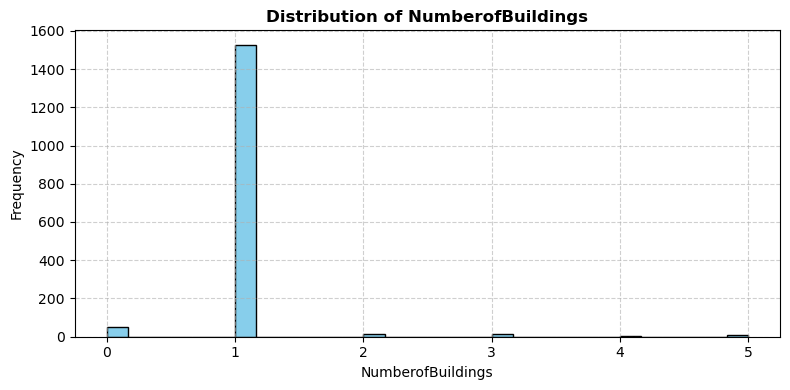

✅ Displayed histogram for NumberofBuildings (trimmed 1st–99th percentile for clarity)


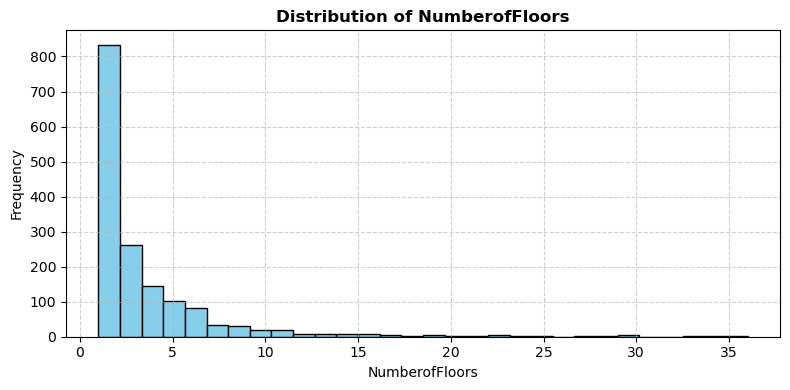

✅ Displayed histogram for NumberofFloors (trimmed 1st–99th percentile for clarity)


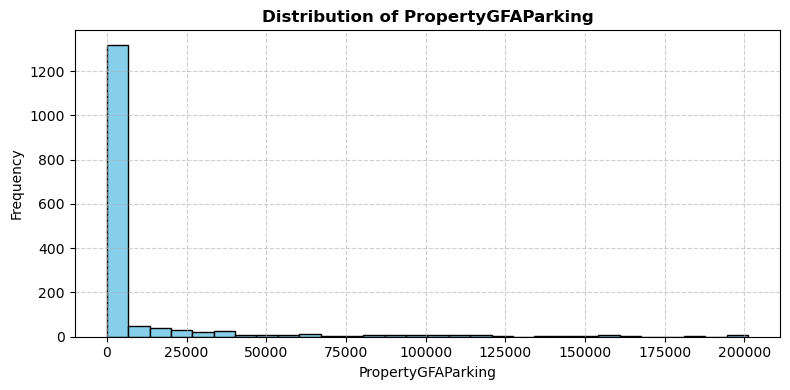

✅ Displayed histogram for PropertyGFAParking (trimmed 1st–99th percentile for clarity)


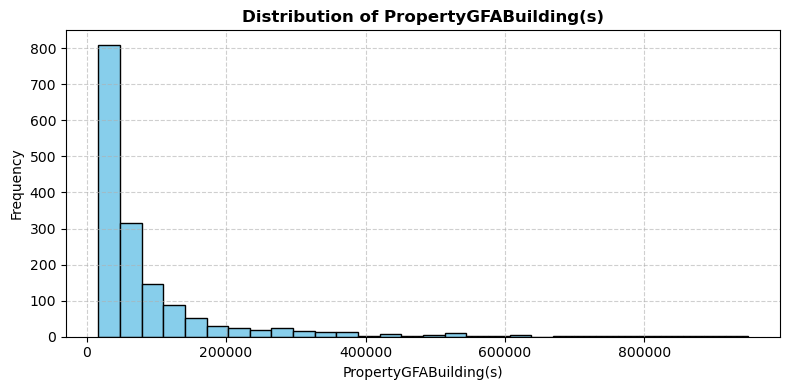

✅ Displayed histogram for PropertyGFABuilding(s) (trimmed 1st–99th percentile for clarity)


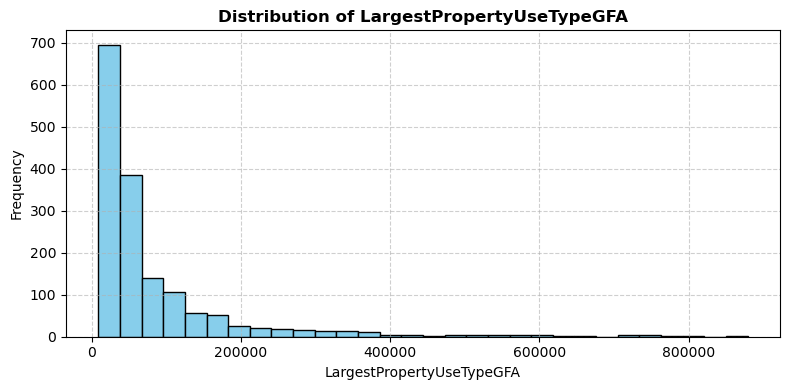

✅ Displayed histogram for LargestPropertyUseTypeGFA (trimmed 1st–99th percentile for clarity)


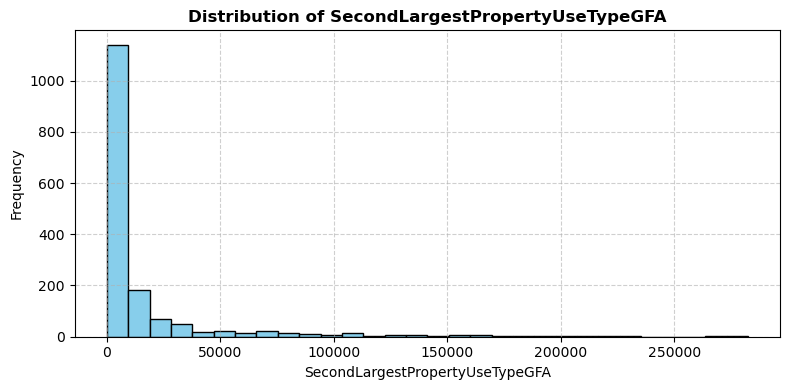

✅ Displayed histogram for SecondLargestPropertyUseTypeGFA (trimmed 1st–99th percentile for clarity)


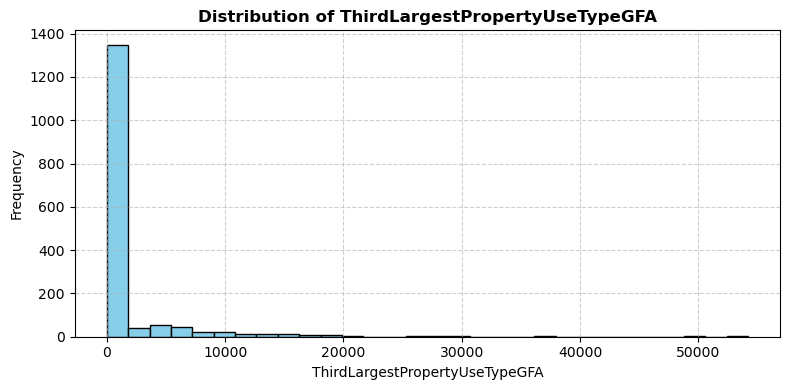

✅ Displayed histogram for ThirdLargestPropertyUseTypeGFA (trimmed 1st–99th percentile for clarity)


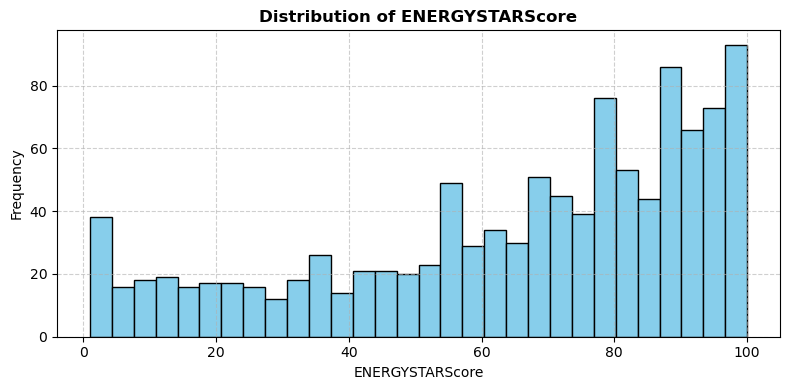

✅ Displayed histogram for ENERGYSTARScore (trimmed 1st–99th percentile for clarity)


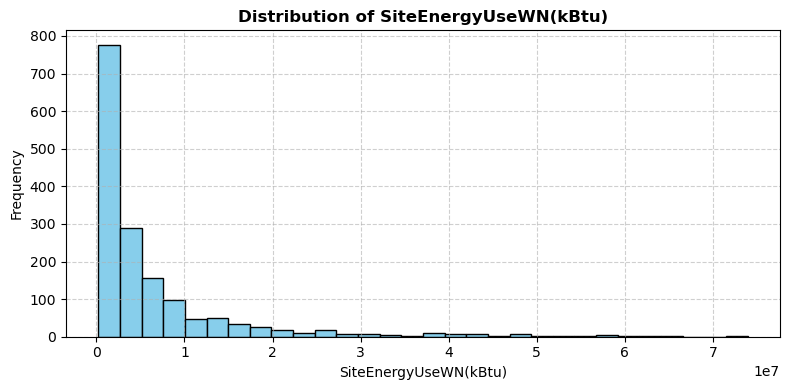

✅ Displayed histogram for SiteEnergyUseWN(kBtu) (trimmed 1st–99th percentile for clarity)


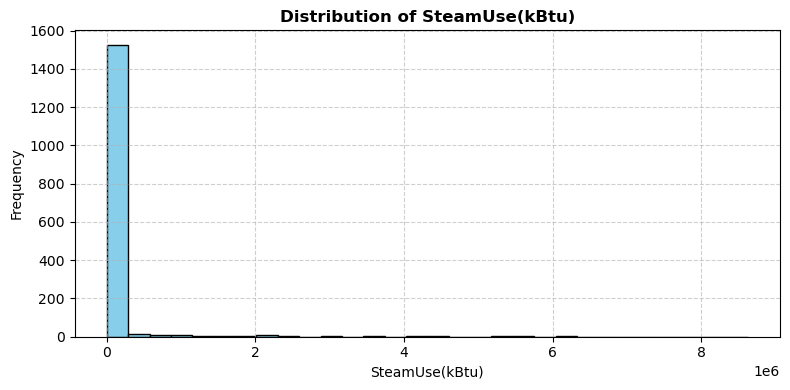

✅ Displayed histogram for SteamUse(kBtu) (trimmed 1st–99th percentile for clarity)


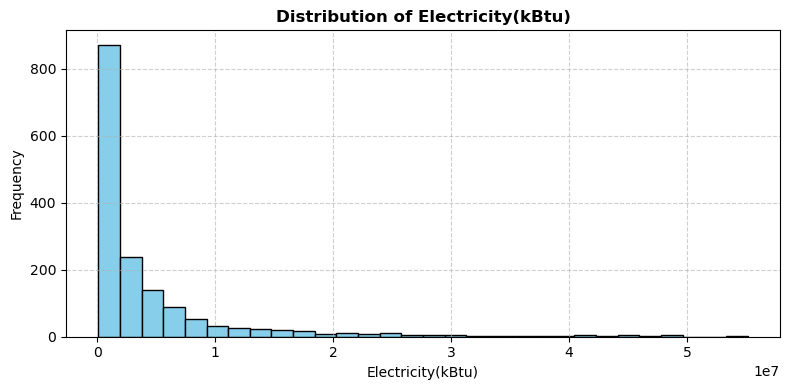

✅ Displayed histogram for Electricity(kBtu) (trimmed 1st–99th percentile for clarity)


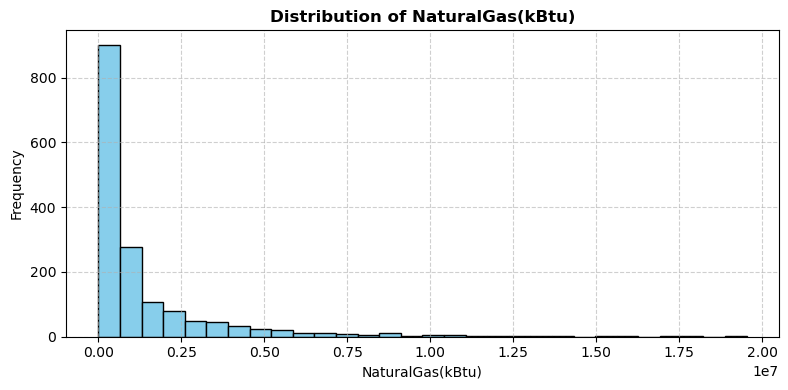

✅ Displayed histogram for NaturalGas(kBtu) (trimmed 1st–99th percentile for clarity)


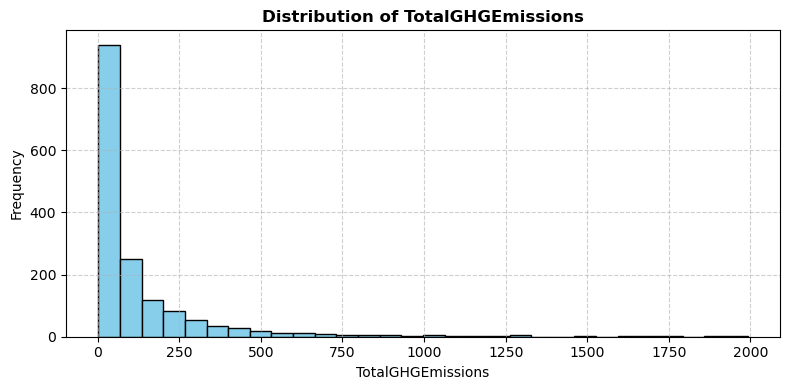

✅ Displayed histogram for TotalGHGEmissions (trimmed 1st–99th percentile for clarity)


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

num_cols = data.select_dtypes(include=[np.number]).columns

for col in num_cols:
    # Extract numeric data
    values = data[col].dropna().astype(float)

    if values.empty:
        print(f"⚠️ Skipping {col} — no non-null values.")
        continue

    # Auto-adjust x-axis by trimming extreme outliers (1st–99th percentile)
    q1, q99 = np.percentile(values, [1, 99])
    filtered = values[(values >= q1) & (values <= q99)]

    plt.figure(figsize=(8, 4))
    plt.hist(filtered, bins=30, color="skyblue", edgecolor="black")
    plt.title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"✅ Displayed histogram for {col} (trimmed 1st–99th percentile for clarity)")


# PAIRPLOTS

✅ Using 14 variables: ['YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)', 'TotalGHGEmissions']
🔹 Applied log₁₀ transform to 'SiteEnergyUseWN(kBtu)'
🔹 Applied log₁₀ transform to 'SteamUse(kBtu)'
🔹 Applied log₁₀ transform to 'Electricity(kBtu)'
🔹 Applied log₁₀ transform to 'NaturalGas(kBtu)'
🔹 Applied log₁₀ transform to 'TotalGHGEmissions'


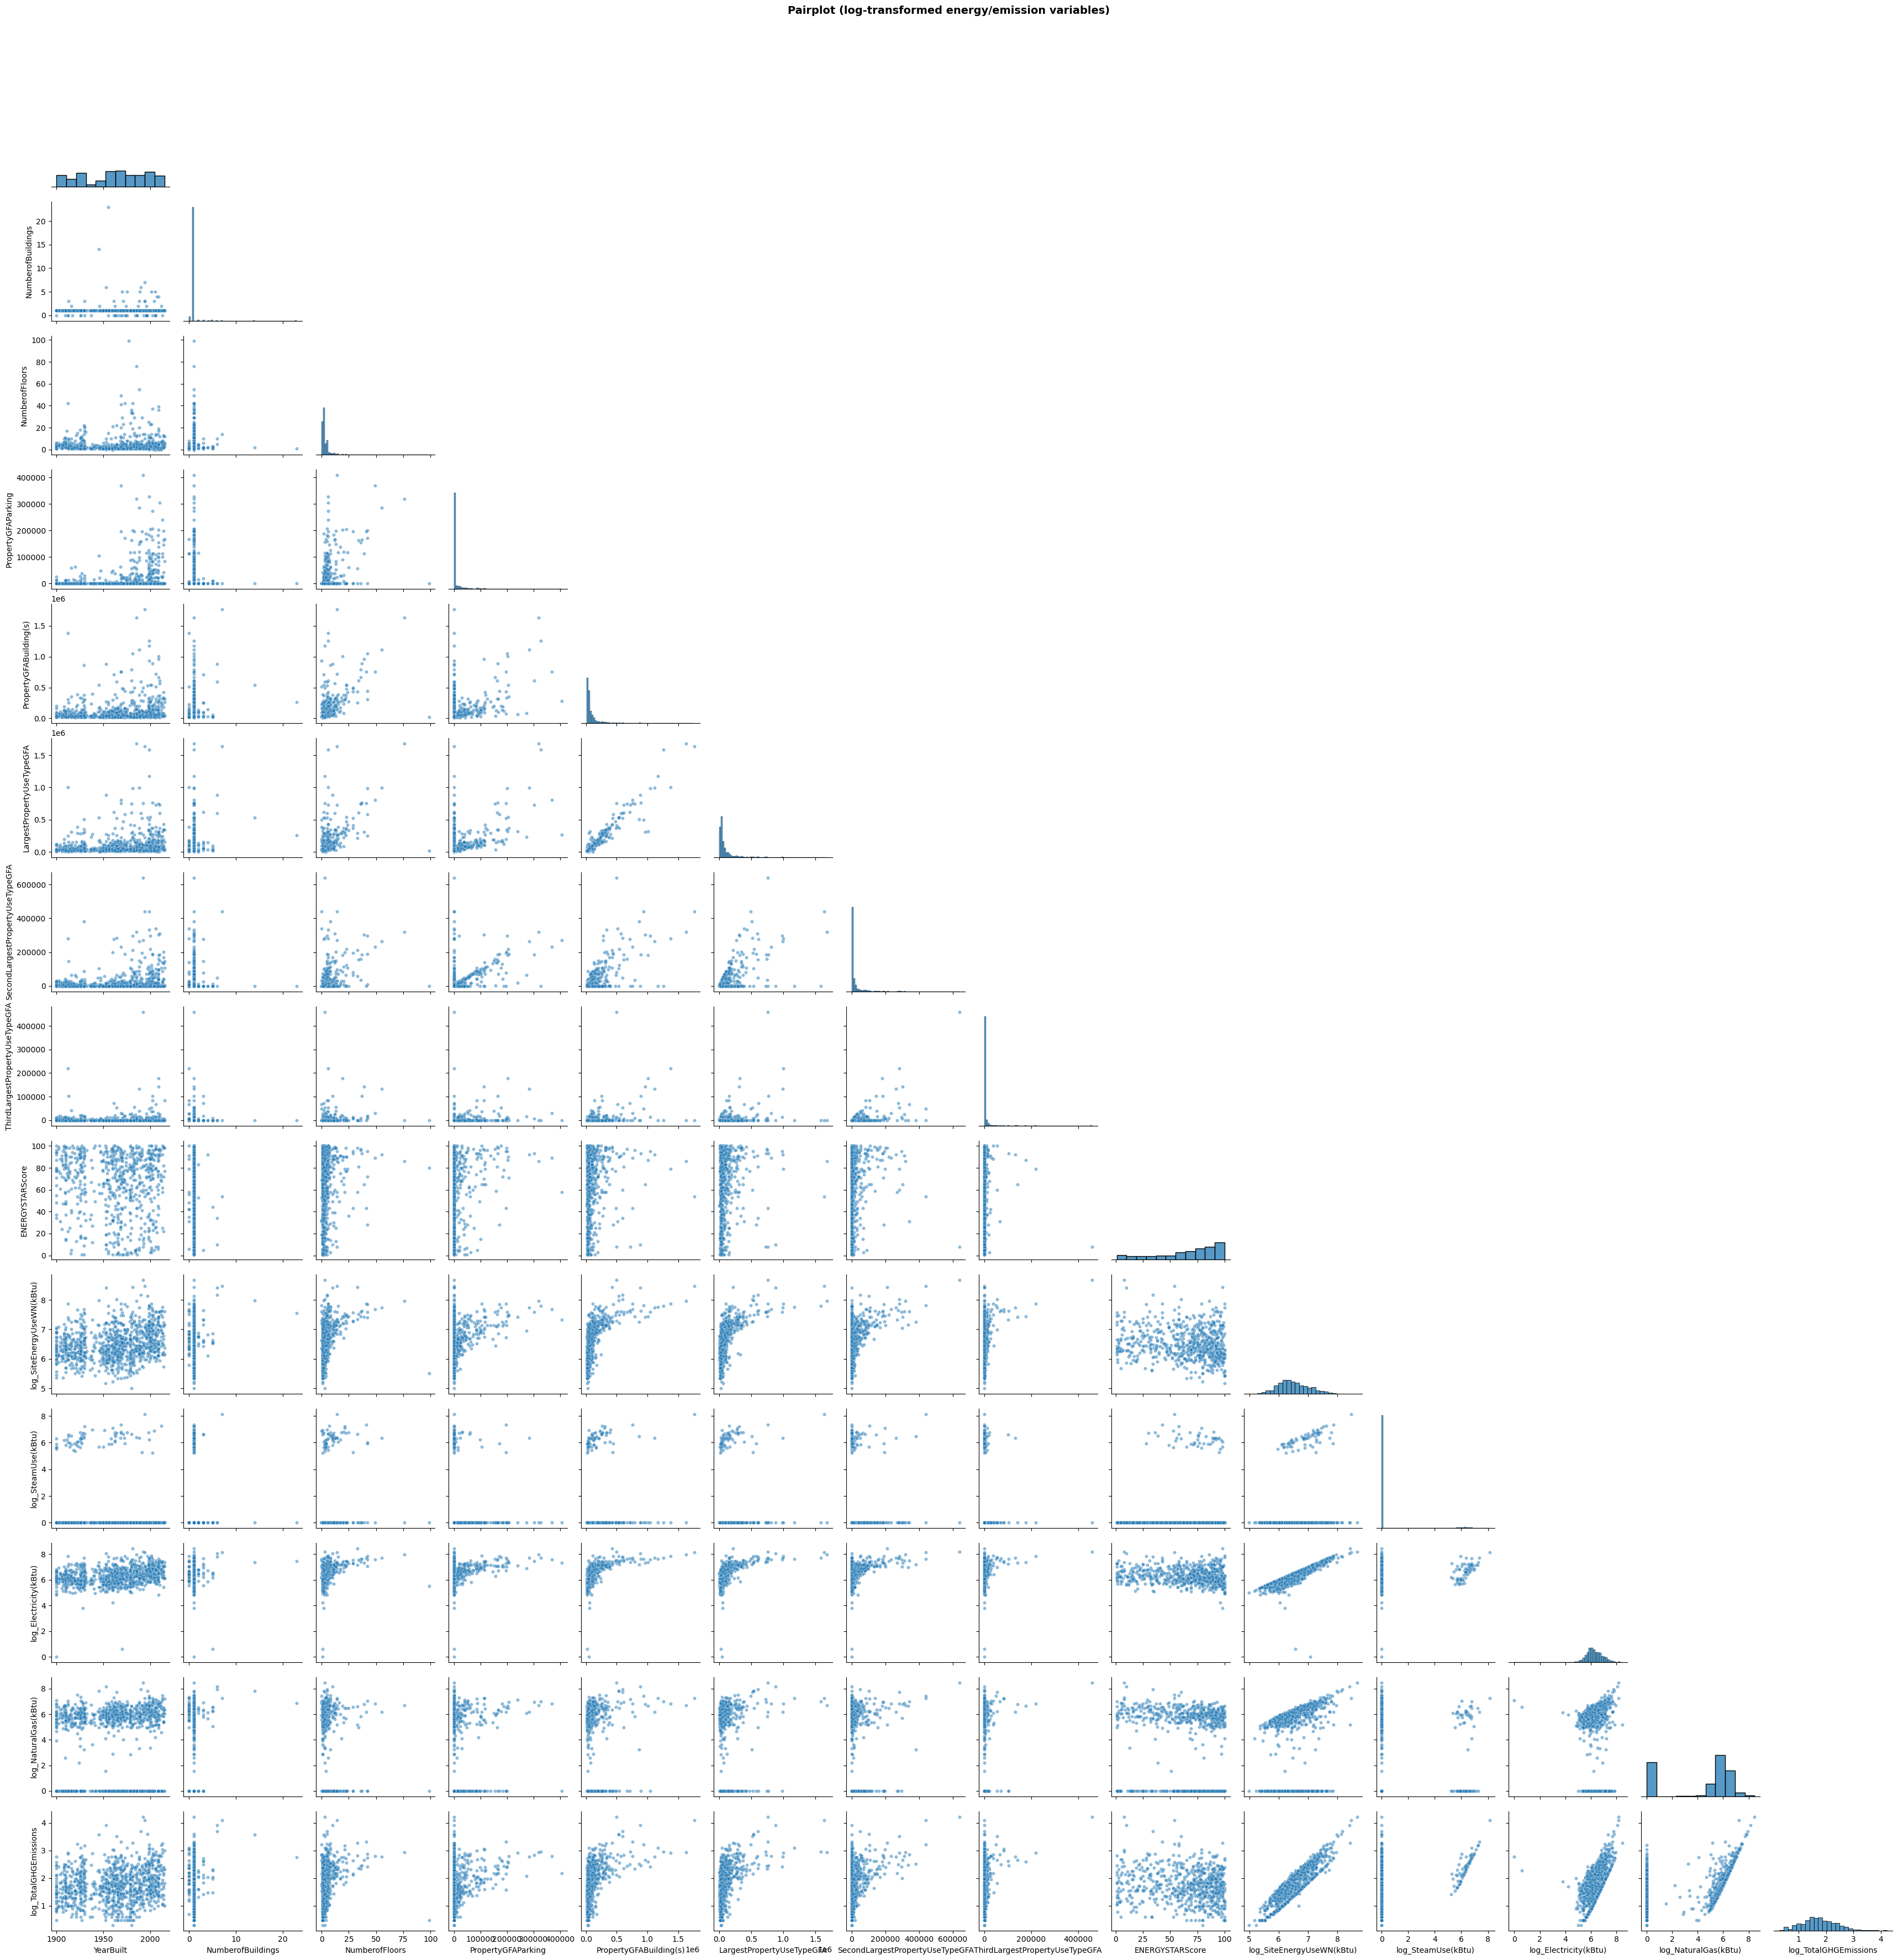

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Key variables (subset of those you listed)
cols = [
    "YearBuilt",
    "NumberofBuildings",
    "NumberofFloors",
    "PropertyGFAParking",
    "PropertyGFABuilding(s)",
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseTypeGFA",
    "ENERGYSTARScore",
    "SiteEnergyUseWN(kBtu)",
    "SteamUse(kBtu)",
    "Electricity(kBtu)",
    "NaturalGas(kBtu)",
    "TotalGHGEmissions"
]

# Filter only existing columns
available = [c for c in cols if c in data.columns]
df_plot = data[available].copy()
print(f"✅ Using {len(available)} variables: {available}")

# Columns to log-transform
log_cols = [
    "SiteEnergyUseWN(kBtu)",
    "SteamUse(kBtu)",
    "Electricity(kBtu)",
    "NaturalGas(kBtu)",
    "TotalGHGEmissions"
]

# Apply log10(x + 1) transform safely (handles zeros)
for col in log_cols:
    if col in df_plot.columns:
        df_plot[f"log_{col}"] = np.log10(df_plot[col].astype(float) + 1)
        print(f"🔹 Applied log₁₀ transform to '{col}'")

# Replace originals with log versions in plotting list
plot_cols = [
    "YearBuilt",
    "NumberofBuildings",
    "NumberofFloors",
    "PropertyGFAParking",
    "PropertyGFABuilding(s)",
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseTypeGFA",
    "ENERGYSTARScore",
    "log_SiteEnergyUseWN(kBtu)",
    "log_SteamUse(kBtu)",
    "log_Electricity(kBtu)",
    "log_NaturalGas(kBtu)",
    "log_TotalGHGEmissions"
]
plot_cols = [c for c in plot_cols if c in df_plot.columns]

# Sample for performance
sampled = df_plot[plot_cols].sample(n=min(1000, len(df_plot)), random_state=42)

# Create pairplot
sns.pairplot(sampled, diag_kind="hist", corner=True, plot_kws={"alpha":0.5, "s":20})
plt.suptitle("Pairplot (log-transformed energy/emission variables)", y=1.02, fontsize=14, fontweight="bold")
plt.show()


# BOXPLOTS

C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\529046950.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


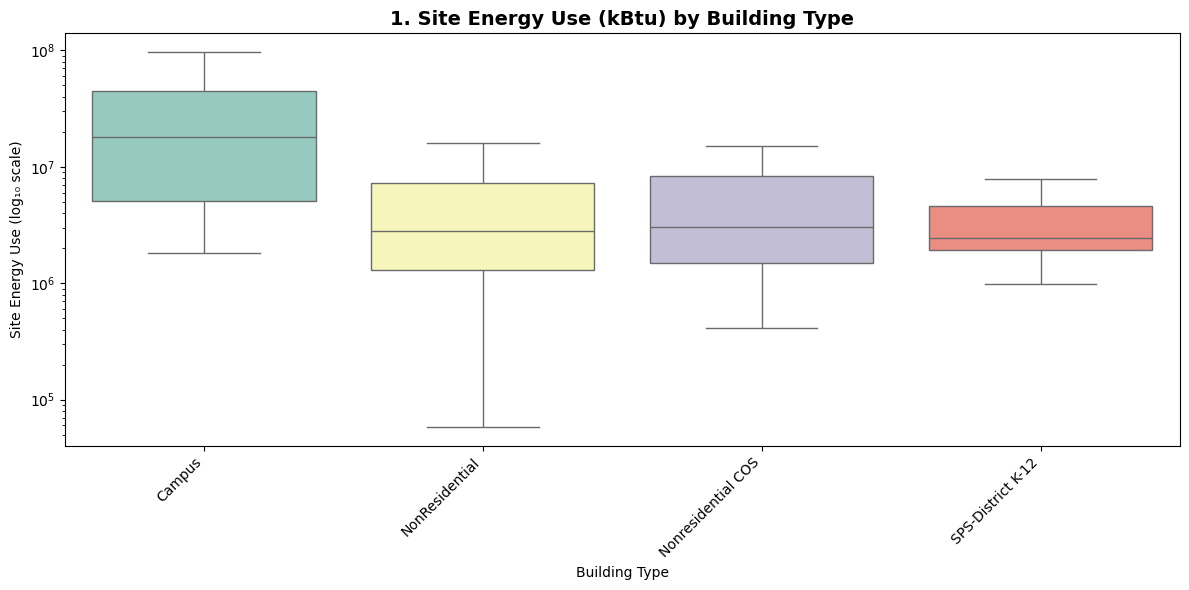

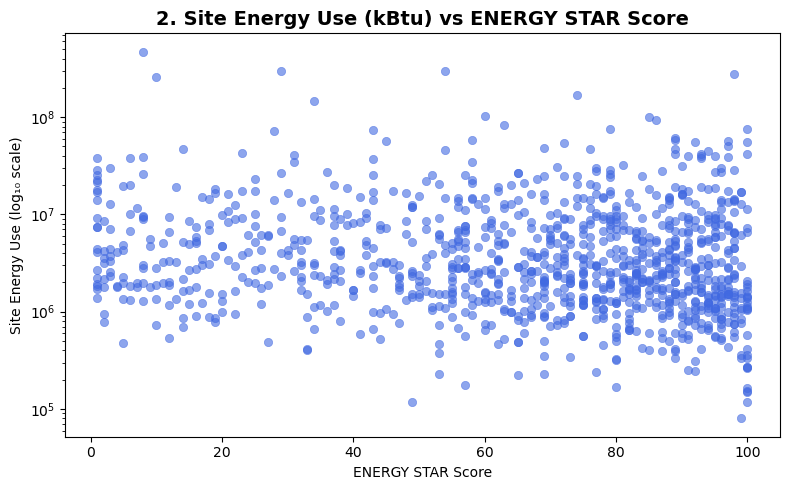

C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\529046950.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


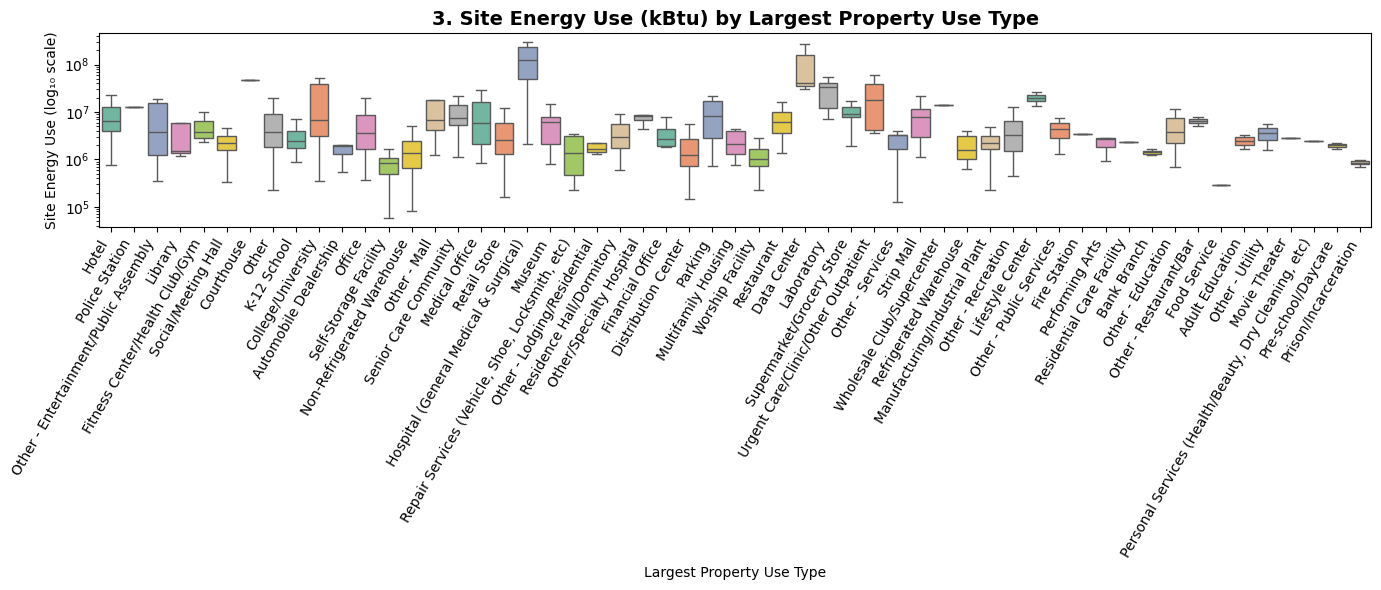

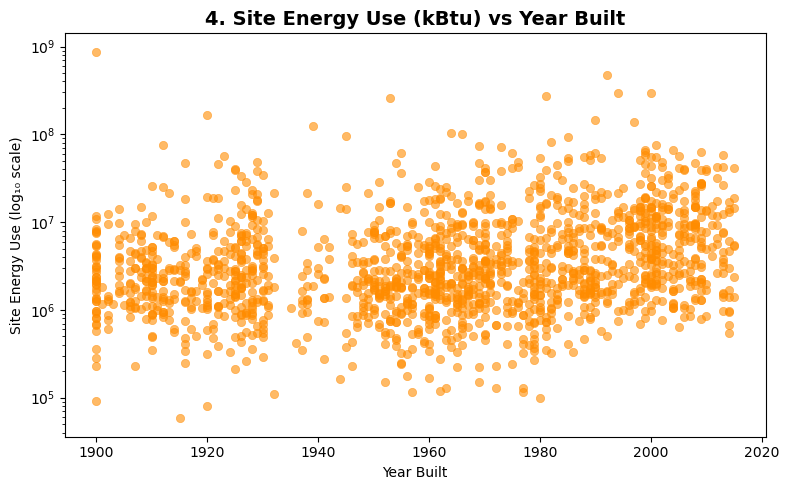

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1️⃣ BuildingType vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=data,
    x="BuildingType",
    y="SiteEnergyUseWN(kBtu)",
    palette="Set3",
    showfliers=False
)
plt.yscale("log")
plt.title("1. Site Energy Use (kBtu) by Building Type", fontsize=14, fontweight="bold")
plt.xlabel("Building Type")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# --- 2️⃣ SiteEnergyUseWN(kBtu) vs ENERGYSTARScore ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="ENERGYSTARScore",
    y="SiteEnergyUseWN(kBtu)",
    alpha=0.6,
    color="royalblue",
    edgecolor=None
)
plt.yscale("log")
plt.title("2. Site Energy Use (kBtu) vs ENERGY STAR Score", fontsize=14, fontweight="bold")
plt.xlabel("ENERGY STAR Score")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.tight_layout()
plt.show()


# --- 3️⃣ LargestPropertyUseType vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=data,
    x="LargestPropertyUseType",
    y="SiteEnergyUseWN(kBtu)",
    palette="Set2",
    showfliers=False
)
plt.yscale("log")
plt.title("3. Site Energy Use (kBtu) by Largest Property Use Type", fontsize=14, fontweight="bold")
plt.xlabel("Largest Property Use Type")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


# --- 4️⃣ YearBuilt vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="YearBuilt",
    y="SiteEnergyUseWN(kBtu)",
    alpha=0.6,
    color="darkorange",
    edgecolor=None
)
plt.yscale("log")
plt.title("4. Site Energy Use (kBtu) vs Year Built", fontsize=14, fontweight="bold")
plt.xlabel("Year Built")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.tight_layout()
plt.show()


In [21]:
import numpy as np
import pandas as pd

# Create binary flag: 1 if score > 0, else 0 (also handles NaN)
data["hasEnergyStarScore"] = np.where(data["ENERGYSTARScore"].fillna(0) > 0, 1, 0)

print("✅ Created new feature: 'hasEnergyStarScore'")
display(data[["ENERGYSTARScore", "hasEnergyStarScore"]].head(10))

# Quick summary
print("\nDistribution of hasEnergyStarScore:")
print(data["hasEnergyStarScore"].value_counts())


✅ Created new feature: 'hasEnergyStarScore'


,ENERGYSTARScore,hasEnergyStarScore
0,60,1
1,61,1
2,43,1
3,56,1
4,75,1
5,<NA>,0
6,27,1
7,<NA>,0
8,43,1
10,30,1



Distribution of hasEnergyStarScore:
hasEnergyStarScore
1    1080
0     550
Name: count, dtype: int64


In [22]:
import pandas as pd
import numpy as np

# 1️⃣ Clean invalid or text entries
data["ENERGYSTARScore"] = pd.to_numeric(data["ENERGYSTARScore"], errors="coerce")

# 2️⃣ Treat 0 and NaN as missing
data.loc[data["ENERGYSTARScore"] == 0, "ENERGYSTARScore"] = np.nan

# 3️⃣ Compute mean ENERGY STAR score by BuildingType
mean_by_type = data.groupby("BuildingType")["ENERGYSTARScore"].mean()

# 4️⃣ Fill missing values with the BuildingType mean
data["ENERGYSTARScore"] = data.apply(
    lambda row: mean_by_type[row["BuildingType"]]
    if pd.isna(row["ENERGYSTARScore"]) and row["BuildingType"] in mean_by_type
    else row["ENERGYSTARScore"],
    axis=1
)

print("✅ Filled missing or zero ENERGY STAR scores using BuildingType mean.")
display(data[["BuildingType", "ENERGYSTARScore"]].head(15))

✅ Filled missing or zero ENERGY STAR scores using BuildingType mean.


C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\2840397010.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_by_type = data.groupby("BuildingType")["ENERGYSTARScore"].mean()


,BuildingType,ENERGYSTARScore
0,NonResidential,60.000000
1,NonResidential,61.000000
2,NonResidential,43.000000
3,NonResidential,56.000000
4,NonResidential,75.000000
5,Nonresidential COS,60.909091
6,NonResidential,27.000000
7,NonResidential,63.593082
8,NonResidential,43.000000
10,NonResidential,30.000000


In [23]:
print("Remaining missing ENERGY STAR scores:", data["ENERGYSTARScore"].isna().sum())
data.groupby("BuildingType")["ENERGYSTARScore"].mean().head(10)


Remaining missing ENERGY STAR scores: 0


C:\Users\shahu\AppData\Local\Temp\ipykernel_34916\715987284.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("BuildingType")["ENERGYSTARScore"].mean().head(10)


BuildingType
Campus                56.600000
NonResidential        63.593082
Nonresidential COS    60.909091
SPS-District K-12     85.259259
Name: ENERGYSTARScore, dtype: float64

# FEATURE ENGINEERING

In [24]:
data.describe()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,hasEnergyStarScore
count,1630.0,1630.0,1630.0,1630.0,1630.0,1630.0,1630.0,1630.0,1630.000000,1630.0,1630.0,1630.0,1630.0,1630.0,1630.000000
mean,1962.005521,1.169939,4.160123,13156.692638,106158.482209,98757.65092,18808.755828,3210.177914,64.455048,8789221.649693,523893.192638,5920307.507362,2004537.000613,188.17362,0.662577
std,32.692861,2.961999,6.630066,42713.437154,285576.694683,278291.037237,51210.451492,18166.162055,23.129719,30902252.56525,5574005.986409,20987303.090037,9469382.191927,759.828728,0.472976
min,1900.0,0.0,0.0,0.0,3636.0,0.0,0.0,0.0,1.000000,58114.0,0.0,0.0,0.0,0.0,0.000000
25%,1930.0,1.0,1.0,0.0,28375.25,25500.0,0.0,0.0,60.000000,1366622.25,0.0,743761.25,0.0,21.0,0.000000
50%,1966.0,1.0,2.0,0.0,47160.0,43525.5,0.0,0.0,63.593082,2787996.5,0.0,1642951.5,525647.0,51.0,1.000000
75%,1989.0,1.0,4.0,0.0,95306.5,92004.5,12863.0,0.0,81.000000,7338307.5,0.0,4971463.75,1530282.0,145.0,1.000000
max,2015.0,111.0,99.0,512608.0,9320156.0,9320156.0,639931.0,459748.0,100.000000,873923712.0,134943456.0,657074389.0,297909000.0,16871.0,1.000000


In [25]:
import pandas as pd
from datetime import datetime

current_year = datetime.now().year  # dynamically gets the current year
data["Age"] = current_year - data["YearBuilt"]

# Replace any negative or invalid ages (from future YearBuilt) with NaN
data.loc[data["Age"] < 0, "Age"] = pd.NA

print(f"✅ Created new feature 'Age' (Current year = {current_year})")
display(data[["YearBuilt", "Age"]].head())


✅ Created new feature 'Age' (Current year = 2025)


,YearBuilt,Age
0,1927,98
1,1996,29
2,1969,56
3,1926,99
4,1980,45


In [26]:
import numpy as np
import pandas as pd

# Avoid division by zero or NaN in the denominator
denominator = data["PropertyGFABuilding(s)"].replace(0, np.nan)

# Compute ratio safely
data["Ratio_LargestPropertyShare"] = data["LargestPropertyUseTypeGFA"] / denominator

# Cap unrealistic ratios > 1.0 (e.g., due to data entry errors)
data.loc[data["Ratio_LargestPropertyShare"] > 1, "Ratio_LargestPropertyShare"] = np.nan

print("✅ Created new feature: 'Ratio_LargestPropertyShare'")
display(data[["LargestPropertyUseTypeGFA", "PropertyGFABuilding(s)", "Ratio_LargestPropertyShare"]].head(10))


✅ Created new feature: 'Ratio_LargestPropertyShare'


,LargestPropertyUseTypeGFA,PropertyGFABuilding(s),Ratio_LargestPropertyShare
0,88434,88434,1.0
1,83880,88502,0.947775
2,756493,759392,0.996182
3,61320,61320,1.0
4,123445,113580,<NA>
5,88830,60090,<NA>
6,81352,83008,0.98005
7,102761,102761,1.0
8,163984,163984,1.0
10,133884,133884,1.0


In [27]:
import numpy as np
import pandas as pd

# Avoid division by zero or NaN in denominator
denominator = data["SiteEnergyUseWN(kBtu)"].replace(0, np.nan)

# Compute ratios safely
data["Ratio_ElectricityShare"] = data["Electricity(kBtu)"] / denominator
data["Ratio_NaturalGasShare"] = data["NaturalGas(kBtu)"] / denominator

# Cap invalid ratios > 1.0 (since a share >100% is not physically possible)
for col in ["Ratio_ElectricityShare", "Ratio_NaturalGasShare"]:
    data.loc[data[col] > 1, col] = np.nan

print("✅ Created new features: 'Ratio_ElectricityShare' and 'Ratio_NaturalGasShare'")
display(data[["Electricity(kBtu)", "NaturalGas(kBtu)", "SiteEnergyUseWN(kBtu)",
              "Ratio_ElectricityShare", "Ratio_NaturalGasShare"]].head(10))


✅ Created new features: 'Ratio_ElectricityShare' and 'Ratio_NaturalGasShare'


,Electricity(kBtu),NaturalGas(kBtu),SiteEnergyUseWN(kBtu),Ratio_ElectricityShare,Ratio_NaturalGasShare
0,3946027,1276453,7456910,0.529177,0.171177
1,3242851,5145082,8664479,0.37427,0.593813
2,49526664,1493800,73937112,0.669849,0.020204
3,2768924,1811213,6946801,0.39859,0.260726
4,5368607,8803998,14656503,0.366295,0.600689
5,7371434,4715182,12581712,0.585885,0.374765
6,2811215,2947580,6062768,0.463685,0.486177
7,3636655,385189,7067882,0.514533,0.054499
8,7297919,6425900,14194054,0.514153,0.452718
10,6187627,4591850,16646930,0.371698,0.275838


In [28]:
import pandas as pd
import numpy as np

# Temporary flags for each energy source
data["S_flag"] = np.where(data["SteamUse(kBtu)"] > 0, "S", "")
data["E_flag"] = np.where(data["Electricity(kBtu)"] > 0, "E", "")
data["N_flag"] = np.where(data["NaturalGas(kBtu)"] > 0, "N", "")

# Concatenate flags to form Energy Mix labels
data["EnergyMix"] = (data["S_flag"] + data["E_flag"] + data["N_flag"]).replace("", np.nan)

# Drop the temporary helper columns
data.drop(columns=["S_flag", "E_flag", "N_flag"], inplace=True)

# Convert to category type for modeling efficiency
data["EnergyMix"] = data["EnergyMix"].astype("category")

# Display summary
print("✅ Created new feature: 'EnergyMix'")
display(data[["SteamUse(kBtu)", "Electricity(kBtu)", "NaturalGas(kBtu)", "EnergyMix"]].head(10))

# Quick frequency check
print("\nEnergy Mix distribution:")
print(data["EnergyMix"].value_counts(dropna=False))


✅ Created new feature: 'EnergyMix'


,SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),EnergyMix
0,2003882,3946027,1276453,SEN
1,0,3242851,5145082,EN
2,21566554,49526664,1493800,SEN
3,2214446,2768924,1811213,SEN
4,0,5368607,8803998,EN
5,0,7371434,4715182,EN
6,0,2811215,2947580,EN
7,2276287,3636655,385189,SEN
8,0,7297919,6425900,EN
10,5237166,6187627,4591850,SEN



Energy Mix distribution:
EnergyMix
EN     1114
E       401
SEN      63
SE       51
N         1
Name: count, dtype: int64


In [29]:
import pandas as pd
import numpy as np

# Helper: columns to check
use_cols = [
    "LargestPropertyUseType",
    "SecondLargestPropertyUseType",
    "ThirdLargestPropertyUseType"
]

# Normalize text: lowercase and strip spaces for consistency
for col in use_cols:
    if col in data.columns:
        data[col] = data[col].astype(str).str.strip().str.lower()

# Define a function to count distinct non-parking uses
def count_non_parking(row):
    types = [t for t in row if pd.notna(t) and t not in ["parking", "nan", "none", ""]]
    return len(set(types))

# Apply the function row-wise
data["isMixedProperty"] = data[use_cols].apply(count_non_parking, axis=1).gt(1).astype(int)

print("✅ Created new feature: 'isMixedProperty' (1 = mixed-use, 0 = single-use)")
display(data[use_cols + ["isMixedProperty"]].head(10))

# Optional: check distribution
print("\nDistribution of isMixedProperty:")
print(data["isMixedProperty"].value_counts())


✅ Created new feature: 'isMixedProperty' (1 = mixed-use, 0 = single-use)


,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,isMixedProperty
0,hotel,nan,nan,0
1,hotel,parking,restaurant,1
2,hotel,nan,nan,0
3,hotel,nan,nan,0
4,hotel,parking,nan,0
5,police station,nan,nan,0
6,hotel,nan,nan,0
7,other - entertainment/public assembly,nan,nan,0
8,hotel,nan,nan,0
10,hotel,nan,nan,0



Distribution of isMixedProperty:
isMixedProperty
0    1034
1     596
Name: count, dtype: int64


In [30]:
# Display all column names
print("✅ Columns in data:")
for col in data.columns:
    print(col)


✅ Columns in data:
BuildingType
ZipCode
YearBuilt
NumberofBuildings
NumberofFloors
PropertyGFAParking
PropertyGFABuilding(s)
LargestPropertyUseType
LargestPropertyUseTypeGFA
SecondLargestPropertyUseType
SecondLargestPropertyUseTypeGFA
ThirdLargestPropertyUseType
ThirdLargestPropertyUseTypeGFA
ENERGYSTARScore
SiteEnergyUseWN(kBtu)
SteamUse(kBtu)
Electricity(kBtu)
NaturalGas(kBtu)
TotalGHGEmissions
hasEnergyStarScore
Age
Ratio_LargestPropertyShare
Ratio_ElectricityShare
Ratio_NaturalGasShare
EnergyMix
isMixedProperty


In [31]:
cols_to_drop = [
    "YearBuilt",
    "SteamUse(kBtu)",
    "Electricity(kBtu)",
    "NaturalGas(kBtu)"
]

data = data.drop(columns=[c for c in cols_to_drop if c in data.columns])
print(f"✅ Dropped {len(cols_to_drop)} columns (only those present).")
print("Remaining columns:", len(data.columns))


✅ Dropped 4 columns (only those present).
Remaining columns: 22


In [32]:
import pandas as pd
import numpy as np

def null_zero_summary(df):
    summary = pd.DataFrame({
        "DataType": df.dtypes.astype(str),  # convert dtype safely to string
        "NaN_Count": df.isna().sum(),
        "NaN_%": round(df.isna().mean() * 100, 2),
    })

    zero_counts = {}
    zero_perc = {}

    for col in df.columns:
        # Use pandas dtype checker instead of np.issubdtype
        if pd.api.types.is_numeric_dtype(df[col]):
            zeros = (df[col] == 0).sum()
            zero_counts[col] = zeros
            zero_perc[col] = round((zeros / len(df)) * 100, 2)
        else:
            zero_counts[col] = "-"
            zero_perc[col] = "-"

    summary["Zero_Count"] = summary.index.map(zero_counts)
    summary["Zero_%"] = summary.index.map(zero_perc)

    return summary.sort_values(by=["NaN_Count", "Zero_Count"], ascending=False)

# Run summary
summary_df = null_zero_summary(data)
print("✅ NaN and Zero Summary per Column:")
display(summary_df)


✅ NaN and Zero Summary per Column:


,DataType,NaN_Count,NaN_%,Zero_Count,Zero_%
Ratio_LargestPropertyShare,Float64,338,20.74,4,0.25
Ratio_ElectricityShare,Float64,31,1.90,1,0.06
BuildingType,category,0,0.00,-,-
ZipCode,object,0,0.00,-,-
LargestPropertyUseType,object,0,0.00,-,-
SecondLargestPropertyUseType,object,0,0.00,-,-
ThirdLargestPropertyUseType,object,0,0.00,-,-
EnergyMix,category,0,0.00,-,-
ThirdLargestPropertyUseTypeGFA,Int64,0,0.00,1304,80.0
PropertyGFAParking,Int64,0,0.00,1299,79.69


In [33]:
import numpy as np
import pandas as pd

# Select columns that start with "Ratio_"
ratio_cols = [col for col in data.columns if col.startswith("Ratio_")]

# Fill NaNs with column mean
for col in ratio_cols:
    mean_value = data[col].mean(skipna=True)
    data[col] = data[col].fillna(mean_value)

print(f"✅ Filled NaN values with column mean for {len(ratio_cols)} Ratio_ features:")
print(ratio_cols)


✅ Filled NaN values with column mean for 3 Ratio_ features:
['Ratio_LargestPropertyShare', 'Ratio_ElectricityShare', 'Ratio_NaturalGasShare']


# correlation matrix

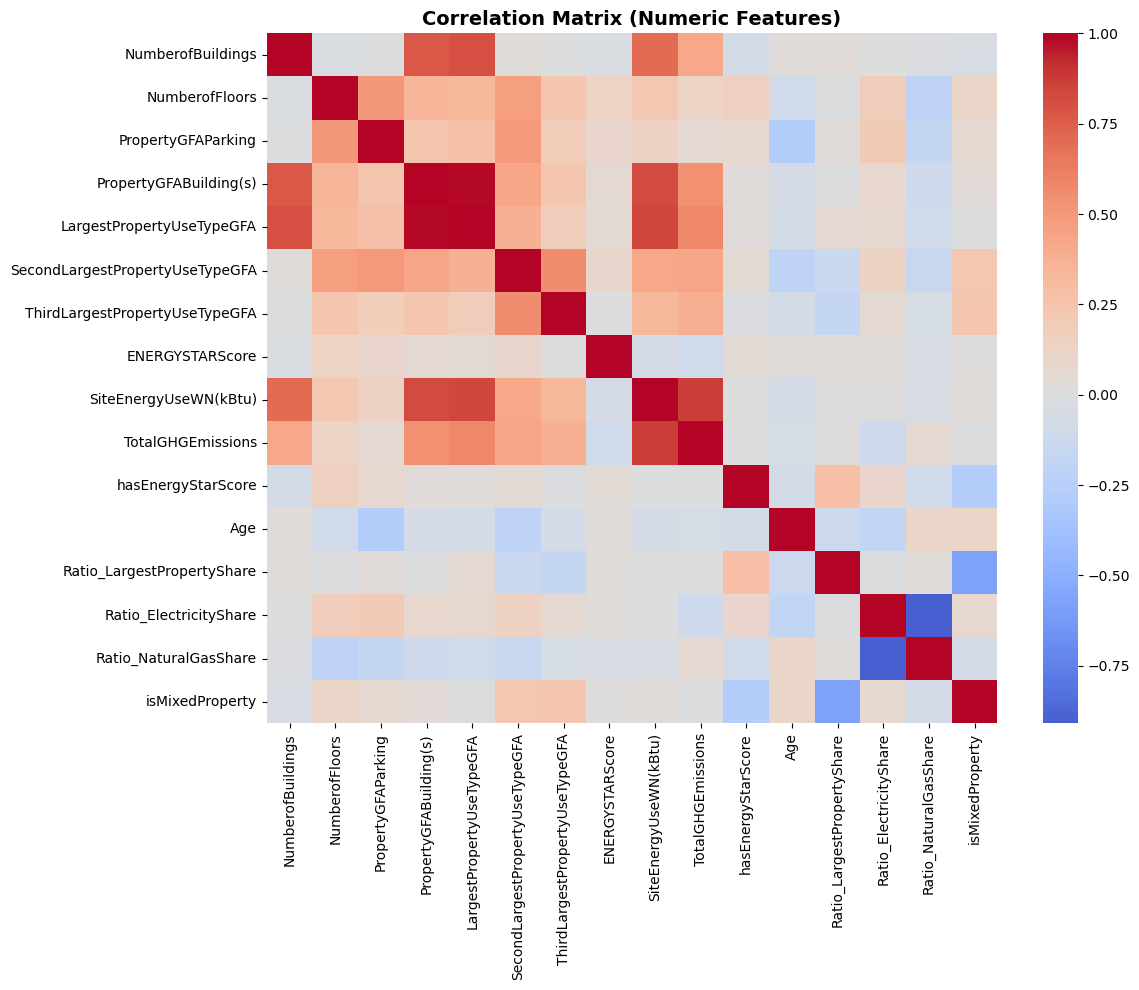

✅ Strong correlations (|r| > 0.7):


,Feature_1,Feature_2,Correlation
0,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.982333
1,Ratio_ElectricityShare,Ratio_NaturalGasShare,0.909112
2,SiteEnergyUseWN(kBtu),TotalGHGEmissions,0.866881
3,LargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),0.842073
4,PropertyGFABuilding(s),SiteEnergyUseWN(kBtu),0.821511
5,NumberofBuildings,LargestPropertyUseTypeGFA,0.799991
6,NumberofBuildings,PropertyGFABuilding(s),0.775676
7,NumberofBuildings,SiteEnergyUseWN(kBtu),0.707175


In [34]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---- Step 1: Compute correlation matrix (numeric only)
numeric_df = data.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method="pearson")

# ---- Step 2: Plot correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Matrix (Numeric Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# ---- Step 3: Extract pairs with |correlation| > 0.7
# Use stack() to unpivot the matrix and filter
corr_pairs = (
    corr_matrix.abs()
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # upper triangle only
    .stack()
    .reset_index()
    .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2", 0: "Correlation"})
)

# Filter strong correlations
high_corr = corr_pairs[corr_pairs["Correlation"] > 0.7].sort_values(
    by="Correlation", ascending=False
).reset_index(drop=True)

print("✅ Strong correlations (|r| > 0.7):")
display(high_corr)




In [35]:
cols_to_drop = [
    "Ratio_NaturalGasShare",
    "PropertyGFABuilding(s)",
    "NumberofBuildings"
   
]

data = data.drop(columns=[c for c in cols_to_drop if c in data.columns])
print(f"✅ Dropped {len(cols_to_drop)} columns (only those present).")
print("Remaining columns:", len(data.columns))

✅ Dropped 3 columns (only those present).
Remaining columns: 19


In [36]:
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,hasEnergyStarScore,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101.0,12,0,hotel,88434,nan,0,nan,0,60.0,7456910,250,1,98,1.0,0.529177,SEN,0
1,NonResidential,98101.0,11,15064,hotel,83880,parking,15064,restaurant,4622,61.0,8664479,296,1,29,0.947775,0.37427,EN,1
2,NonResidential,98101.0,41,196718,hotel,756493,nan,0,nan,0,43.0,73937112,2089,1,56,0.996182,0.669849,SEN,0
3,NonResidential,98101.0,10,0,hotel,61320,nan,0,nan,0,56.0,6946801,286,1,99,1.0,0.39859,SEN,0
4,NonResidential,98121.0,18,62000,hotel,123445,parking,68009,nan,0,75.0,14656503,505,1,45,0.850914,0.366295,EN,0


In [37]:
import pandas as pd
import numpy as np

# Copy to preserve original
data_clean = data.copy()

# Variables to clean
target_cols = ["TotalGHGEmissions", "SiteEnergyUseWN(kBtu)"]

# Initialize summary table
removed_summary = []

initial_rows = len(data_clean)

for col in target_cols:
    if col in data_clean.columns:
        p99 = data_clean[col].quantile(0.99)
        before = len(data_clean)
        data_clean = data_clean[data_clean[col] <= p99]
        after = len(data_clean)
        removed = before - after
        removed_summary.append({
            "Column": col,
            "99th Percentile": round(p99, 2),
            "Rows_Removed": removed,
            "Rows_Remaining": after
        })

# Convert to summary dataframe
removed_df = pd.DataFrame(removed_summary)

print("✅ Outlier removal summary (99th percentile):")
display(removed_df)

print(f"Total rows before filtering: {initial_rows}")
print(f"Total rows after filtering: {len(data_clean)}")
print(f"Total rows deleted overall: {initial_rows - len(data_clean)}")
data = data_clean

✅ Outlier removal summary (99th percentile):


,Column,99th Percentile,Rows_Removed,Rows_Remaining
0,TotalGHGEmissions,2037.15,17,1613
1,SiteEnergyUseWN(kBtu),54960673.76,17,1596


Total rows before filtering: 1630
Total rows after filtering: 1596
Total rows deleted overall: 34


In [38]:
import pandas as pd
from pathlib import Path

# Define output path
output_path = Path(r"C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs")


# Export to Excel
file_path = output_path / "data_modelisation.xlsx"
data.to_excel(file_path, index=False)

print(f"✅ Data successfully exported to: {file_path.resolve()}")


✅ Data successfully exported to: C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\data_modelisation.xlsx
